<a href="https://colab.research.google.com/github/MuhammadAmaan178/Demand-Lens/blob/main/notebooks/DLens_01_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
path = "/content/drive/MyDrive/DemandLens/Data/preprocessed/"
cal = pd.read_csv(path + "calendar.csv")
prices = pd.read_csv(path + "sell_prices.csv")
sales = pd.read_csv(path + "sales_train_evaluation.csv")

## **DemandLens - Dataset (M5 Forecasting)**

FILE 1: calendar.csv (date information, 14 columns)
1. date         : Actual calendar date (e.g. 2011-01-29)
2. wm_yr_wk     : Walmart week ID, used to join with the price file
3. weekday      : Day name (Monday, Tuesday, ...)
4. wday         : Day number in the week (1 to 7)
5. month        : Month number (1 to 12)
6. year         : Year
7. d            : Day label (d_1, d_2, ...), used to join with the sales file
8. event_name_1 : Name of a special event on that day (empty if none)
9. event_type_1 : Type of that event (Sporting, Cultural, National, Religious)
10. event_name_2 : Second event on the same day (rare)
11. event_type_2 : Type of the second event (rare)
12. snap_CA      : 1 if SNAP food-assistance purchases were allowed in California that day, else 0
13. snap_TX      : Same SNAP flag for Texas
14. snap_WI      : Same SNAP flag for Wisconsin


In [ ]:
cal.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


FILE 2: sell_prices.csv (weekly prices, 4 columns)
1. store_id     : Store code (e.g. CA_1)
2. item_id      : Product code
3. wm_yr_wk     : Walmart week ID
4. sell_price   : Price of the item in that store during that week (US dollars)
Note: a missing item/week row usually means the item was not on sale that week.

In [ ]:
prices.head()

,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


FILE 3: sales_train_evaluation.csv (daily unit sales, 1947 columns)
1. id           : Unique row ID combining item, store and file type
2. item_id      : Product code
3. dept_id      : Department of the product (e.g. FOODS_1)
4. cat_id       : Category (FOODS, HOUSEHOLD, HOBBIES)
5. store_id     : Store code
6. state_id     : State code (CA, TX, WI)
7. d_1 to d_1941: Units sold of that item in that store on each day (1941 columns)


In [ ]:
sales.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4,...,d_1932,d_1933,d_1934,d_1935,d_1936,d_1937,d_1938,d_1939,d_1940,d_1941
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,2,4,0,0,0,0,3,3,0,1
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,1,2,1,1,0,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,0,2,0,0,0,2,3,0,1
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,1,1,0,4,0,1,3,0,2,6
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0,...,0,0,0,2,1,0,0,2,1,0


HOW THE FILES CONNECT
1. Sales + Calendar : join on d
2. Sales + Prices   : join on store_id, item_id and wm_yr_wk (week comes from calendar)

NOTES FOR OUR PROJECT
1. d_1 to d_1941 is wide format. We melt it into one row per item per day, and the values become our target column "sales".
2. Many daily values are 0. This does not always mean a stockout, it can mean no customer bought the item.
3. We keep only CA_1 and FOODS, so state_id, snap_TX and snap_WI can be dropped.

In [ ]:
cal.shape

(1969, 14)

In [ ]:
prices.shape

(6841121, 4)

In [ ]:
sales.shape

(30490, 1947)

In [ ]:
sales.iloc[:, :10].head()

,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


In [ ]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30490 entries, 0 to 30489
Columns: 1947 entries, id to d_1941
dtypes: int64(1941), object(6)
memory usage: 452.9+ MB


In [ ]:
prices.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6841121 entries, 0 to 6841120
Data columns (total 4 columns):
 #   Column      Dtype  
---  ------      -----  
 0   store_id    object 
 1   item_id     object 
 2   wm_yr_wk    int64  
 3   sell_price  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 208.8+ MB


In [ ]:
cal.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1969 entries, 0 to 1968
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   date          1969 non-null   object
 1   wm_yr_wk      1969 non-null   int64 
 2   weekday       1969 non-null   object
 3   wday          1969 non-null   int64 
 4   month         1969 non-null   int64 
 5   year          1969 non-null   int64 
 6   d             1969 non-null   object
 7   event_name_1  162 non-null    object
 8   event_type_1  162 non-null    object
 9   event_name_2  5 non-null      object
 10  event_type_2  5 non-null      object
 11  snap_CA       1969 non-null   int64 
 12  snap_TX       1969 non-null   int64 
 13  snap_WI       1969 non-null   int64 
dtypes: int64(7), object(7)
memory usage: 215.5+ KB


In [ ]:
cal.isna().sum(), prices.isna().sum(), sales.isna().sum().sum()

(date               0
 wm_yr_wk           0
 weekday            0
 wday               0
 month              0
 year               0
 d                  0
 event_name_1    1807
 event_type_1    1807
 event_name_2    1964
 event_type_2    1964
 snap_CA            0
 snap_TX            0
 snap_WI            0
 dtype: int64,
 store_id      0
 item_id       0
 wm_yr_wk      0
 sell_price    0
 dtype: int64,
 np.int64(0))

In [ ]:
sales.duplicated().sum()

np.int64(0)

In [ ]:
prices.duplicated().sum()

np.int64(0)

In [ ]:
cal.duplicated().sum()

np.int64(0)

In [ ]:
sales["store_id"].unique()

array(['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1',
       'WI_2', 'WI_3'], dtype=object)

In [ ]:
sales["cat_id"].unique()

array(['HOBBIES', 'HOUSEHOLD', 'FOODS'], dtype=object)

In [ ]:
sales["dept_id"].unique()

array(['HOBBIES_1', 'HOBBIES_2', 'HOUSEHOLD_1', 'HOUSEHOLD_2', 'FOODS_1',
       'FOODS_2', 'FOODS_3'], dtype=object)

In [ ]:
sales["item_id"].unique()

array(['HOBBIES_1_001', 'HOBBIES_1_002', 'HOBBIES_1_003', ...,
       'FOODS_3_825', 'FOODS_3_826', 'FOODS_3_827'],
      shape=(3049,), dtype=object)

In [ ]:
#using this to make pandas display output properly as its was showing in scientific notation format
pd.options.display.float_format = '{:,.2f}'.format

prices["sell_price"].describe()

,sell_price
count,"6,841,121.00"
mean,4.41
std,3.41
min,0.01
25%,2.18
50%,3.47
75%,5.84
max,107.32


In [ ]:
cal["date"].min(), cal["date"].max()

('2011-01-29', '2016-06-19')

## **EDA**

In [ ]:
cal["date"] = pd.to_datetime(cal["date"]) # "date" is text, so we convert it to a real date for correct charts and time-based splits
cal1 = cal.iloc[:1941].copy() # the calendar has 1969 days (using shape rows) but sales has only 1941, so we remove the 28 extra days.
day_cols = [c for c in sales.columns if c.startswith("d_")]  # we need a list of only the d_1 to d_1941 columns, because the other 6 columns are text.
cal1["total_sales"] = sales[day_cols].sum().values # extracting the total sales per day

In [ ]:
cal1.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,total_sales
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0,32631
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0,31749
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0,23783
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0,25412
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1,19146


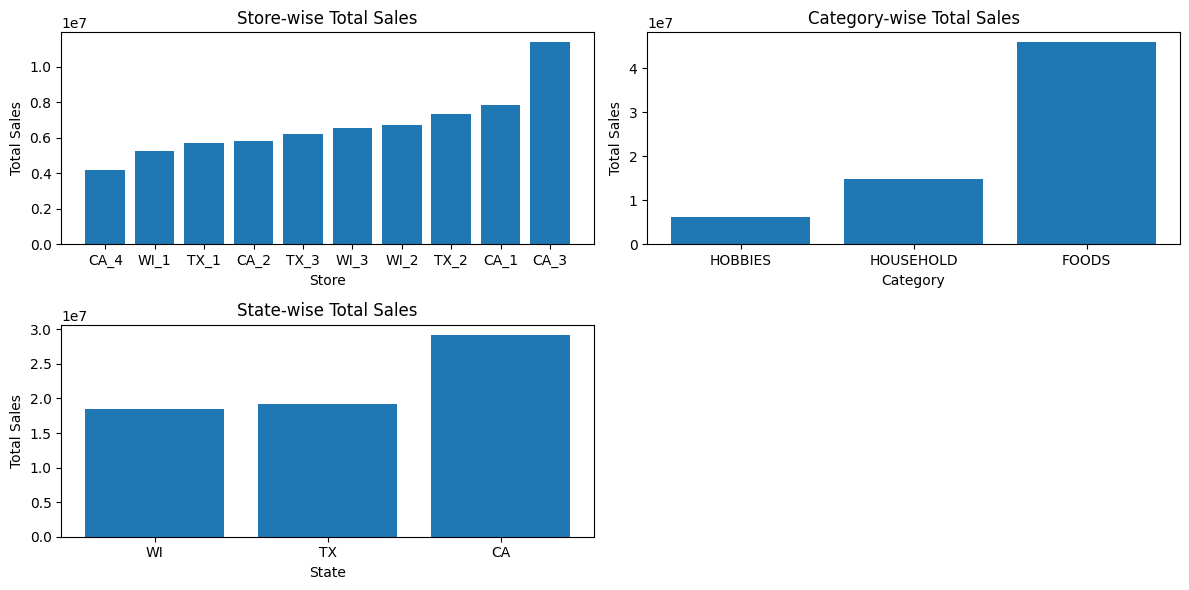

In [ ]:
# Store-wise Total Sales
store_sales = sales.groupby("store_id")[day_cols].sum().sum(axis=1)

plt.figure(figsize=(12, 6))

plt.subplot(2, 2, 1)
plt.bar(store_sales.sort_values().index, store_sales.sort_values().values)
plt.title("Store-wise Total Sales")
plt.xlabel("Store")
plt.ylabel("Total Sales")


# Category-wise Total Sales
category_sales = sales.groupby("cat_id")[day_cols].sum().sum(axis=1)

plt.subplot(2, 2, 2)
plt.bar(category_sales.sort_values().index, category_sales.sort_values().values)
plt.title("Category-wise Total Sales")
plt.xlabel("Category")
plt.ylabel("Total Sales")

# State-wise Total Sales
category_state = sales.groupby("state_id")[day_cols].sum().sum(axis=1)

plt.subplot(2, 2, 3)
plt.bar(category_state.sort_values().index, category_state.sort_values().values)
plt.title("State-wise Total Sales")
plt.xlabel("State")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

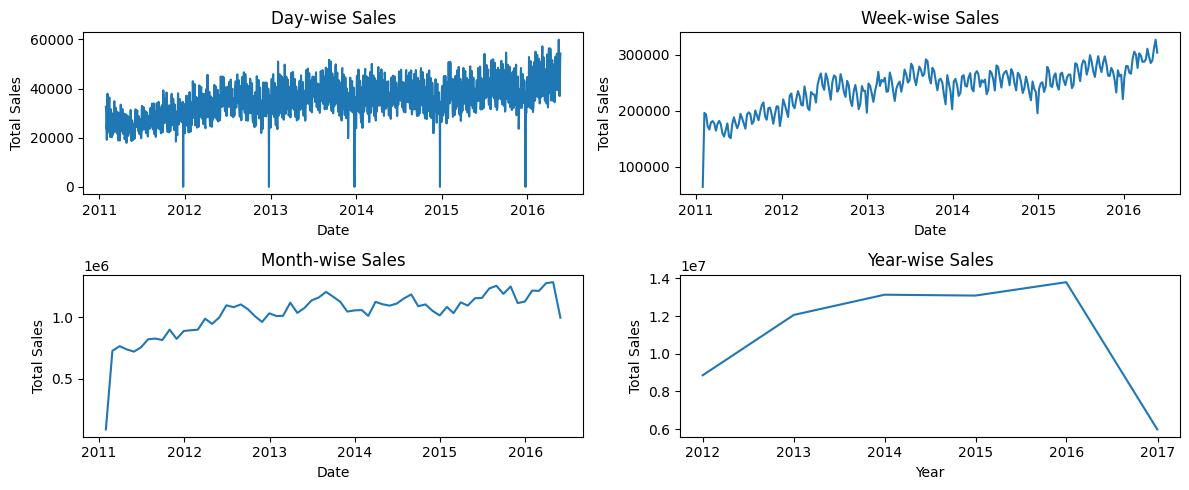

In [ ]:
daily = cal1.set_index("date")["total_sales"]
# 1. Day-wise
day_wise = daily

# 2. Week-wise
week_wise = daily.resample("W").sum()

# 3. Month-wise
month_wise = daily.resample("ME").sum()

# 4. Year-wise
year_wise = daily.resample("YE").sum()

plt.figure(figsize=(12, 5))
# Day-wise
plt.subplot(2, 2, 1)
plt.plot(day_wise)
plt.title("Day-wise Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")

# Week-wise
plt.subplot(2, 2, 2)
plt.plot(week_wise)
plt.title("Week-wise Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")

# Month-wise
plt.subplot(2, 2, 3)
plt.plot(month_wise)
plt.title("Month-wise Sales")
plt.xlabel("Date")
plt.ylabel("Total Sales")

# Year-wise
plt.subplot(2, 2, 4)
plt.plot(year_wise)
plt.title("Year-wise Sales")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

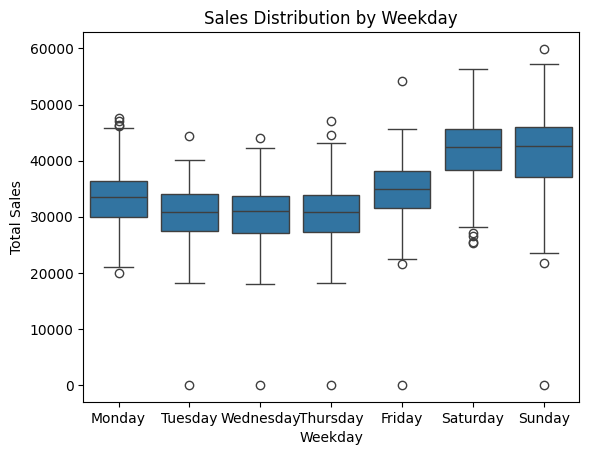

In [ ]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]

sns.boxplot(x="weekday", y="total_sales", data=cal1, order=order)
plt.title("Sales Distribution by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Total Sales")
plt.show()

In [ ]:
cal1.nsmallest(10, "total_sales")[["date", "total_sales", "event_name_1"]]

,date,total_sales,event_name_1
696,2012-12-25,11,Christmas
330,2011-12-25,13,Christmas
1791,2015-12-25,14,Christmas
1061,2013-12-25,20,Christmas
1426,2014-12-25,20,Christmas
88,2011-04-27,17929,NaN
87,2011-04-26,18113,Pesach End
89,2011-04-28,18145,NaN
299,2011-11-24,18427,Thanksgiving
110,2011-05-19,18684,NaN


In [ ]:
closed_dates = cal1.loc[cal1["total_sales"] < 100, "date"]
closed_dates

,date
330,2011-12-25
696,2012-12-25
1061,2013-12-25
1426,2014-12-25
1791,2015-12-25


Observation: The 5 lowest-sales days are all Christmas (25 Dec 2011 to 2015), with total sales of only 11 to 20. The next lowest day has 17,929.
Conclusion: The stores were almost closed on these days, so this is not normal demand. We remove these 5 days before training.

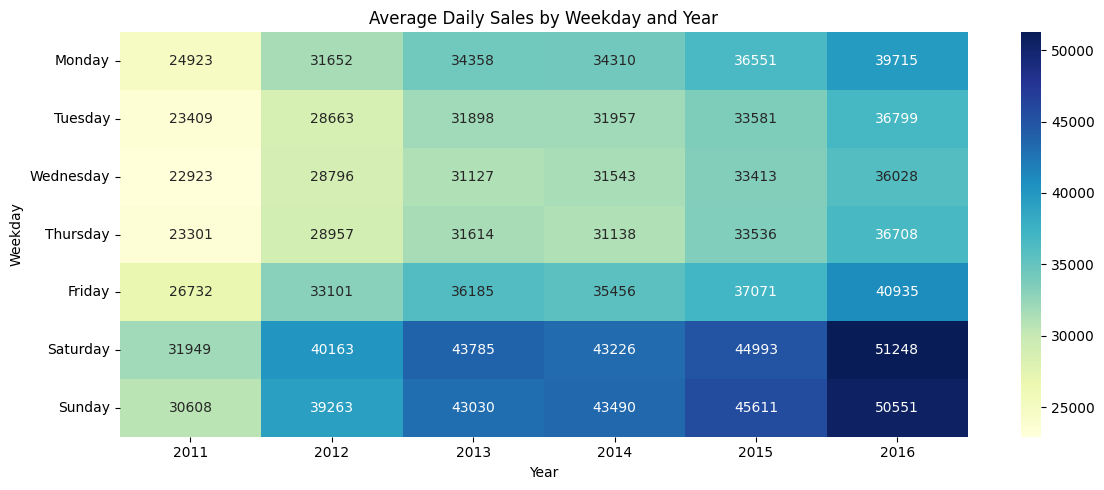

In [ ]:
cal1["weekday"] = cal1["date"].dt.day_name()
cal1["year"] = cal1["date"].dt.year

# Average sales for each weekday per year
heatmap_data = cal1.pivot_table(
    index="weekday",
    columns="year",
    values="total_sales",
    aggfunc="mean"
)

# Arrange weekdays in correct order
heatmap_data = heatmap_data.reindex([
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
])

plt.figure(figsize=(12, 5))
sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="YlGnBu")
plt.title("Average Daily Sales by Weekday and Year")
plt.xlabel("Year")
plt.ylabel("Weekday")

plt.tight_layout()
plt.show()

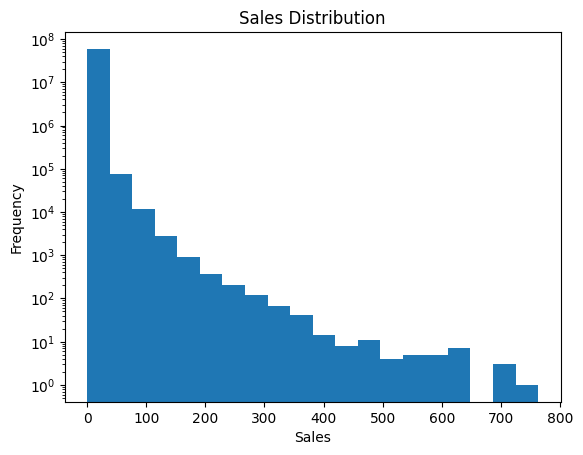

In [ ]:
sales_values = sales[day_cols].values.flatten()

plt.hist(sales_values, bins=20)
plt.yscale("log")
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")

plt.show()

In [ ]:
print("Zero Sales Percentage - ",(sales[day_cols] == 0).mean().mean() * 100)     # overall zero %

Zero Sales Percentage -  67.9977658404061


Graph: Distribution of daily sales for all items (y-axis is log scale).
Observation: Sales are heavily right-skewed. Most days have very small sales (many are zero), and only a few days have very high sales (up to about 700).
Conclusion: Because of the many zero-sales days (<X>% overall), MAPE is not reliable. We use WAPE as the main metric, along with MAE and RMSE.

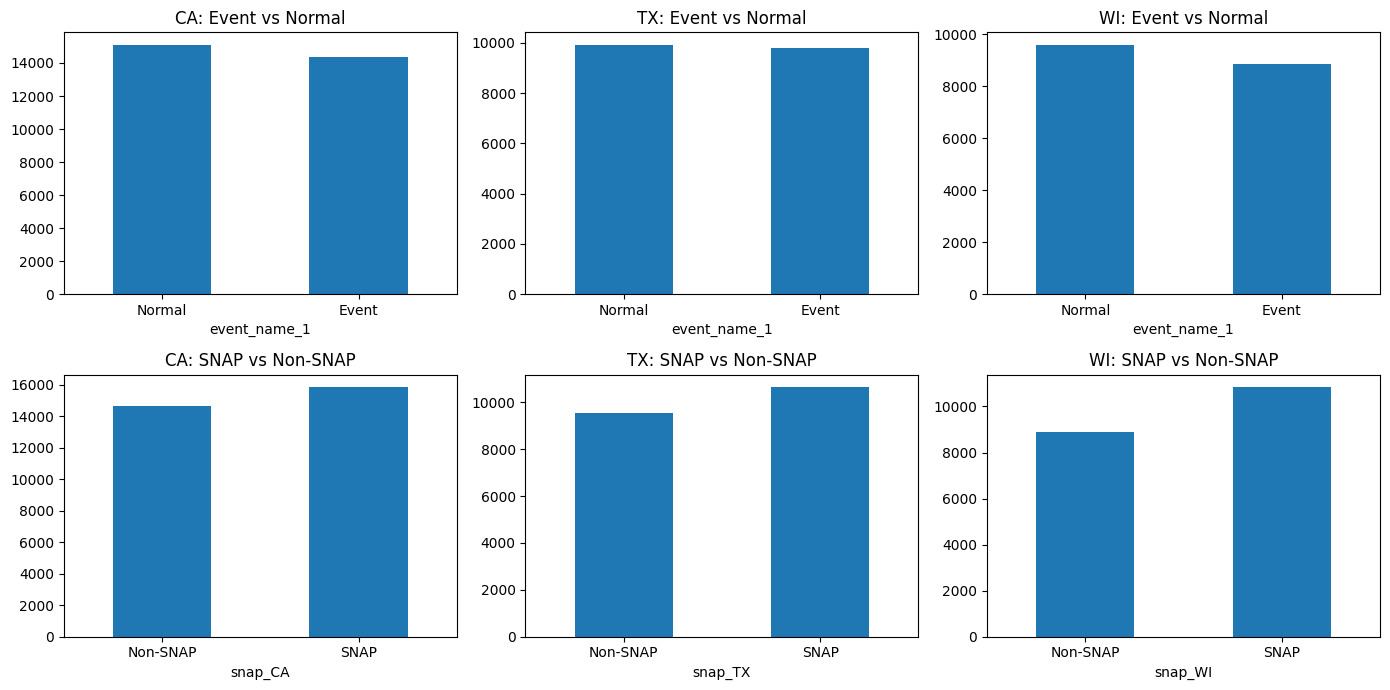

In [ ]:
states = ["CA", "TX", "WI"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))

for i, s in enumerate(states):
    # daily total sales of each state
    cal1["state_sales"] = sales[sales["state_id"] == s][day_cols].sum().values

    # row 1: event vs normal
    cal1.groupby(cal1["event_name_1"].notna())["state_sales"].mean().plot(kind="bar", ax=axes[0, i])
    axes[0, i].set_title(s + ": Event vs Normal")
    axes[0, i].set_xticklabels(["Normal", "Event"], rotation=0)

    # row 2: SNAP vs non-SNAP (each state have its own chart)
    cal1.groupby("snap_" + s)["state_sales"].mean().plot(kind="bar", ax=axes[1, i])
    axes[1, i].set_title(s + ": SNAP vs Non-SNAP")
    axes[1, i].set_xticklabels(["Non-SNAP", "SNAP"], rotation=0)

plt.tight_layout()
plt.show()

Graph: Average daily sales on event days vs normal days (top row) and on SNAP days vs non-SNAP days (bottom row), for CA, TX and WI.
Observation: In all three states, there is not much difference between normal days and event days. There is a visible difference between SNAP and non-SNAP days: SNAP means days when food-assistance purchases are allowed, and sales are higher on those days in all three states.
Conclusion: SNAP days seem to increase sales, so we keep snap_CA, snap_TX and snap_WI as features. Event days show little effect on average, but we still create a has_event feature and check its importance in the model.

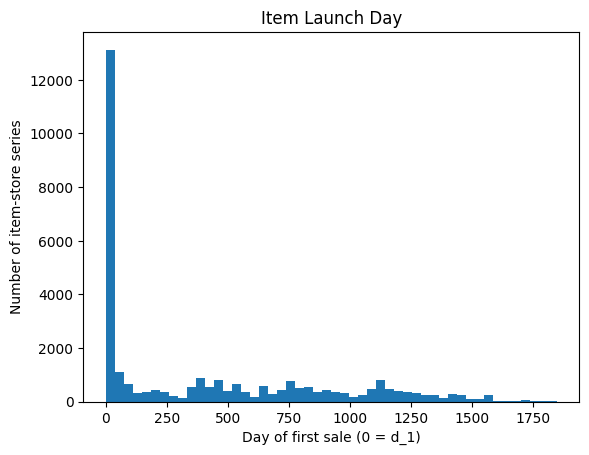

In [ ]:
first_sale = (sales[day_cols].values > 0).argmax(axis=1)

plt.hist(first_sale, bins=50)
plt.title("Item Launch Day")
plt.xlabel("Day of first sale (0 = d_1)")
plt.ylabel("Number of item-store series")
plt.show()

In [ ]:
(sales[day_cols].sum(axis=1) == 0).sum()

np.int64(0)

Graph: Day of the first sale for each item-store series (0 = d_1).
Observation: About 13,000 of the 30,490 series make their first sale in the first ~40 days, so they were on sale from the start. The rest of the series make their first sale later, spread across the whole timeline, so they were added to the stores later. A check shows that no series has zero sales for all 1,941 days, so every series has a valid first-sale day.
Why it matters: Before an item's first sale, the sales are 0 because the item was not on sale yet, not because customers did not want it. If we keep these rows, the model will wrongly learn that demand is zero, and forecasts for new items will be too low.
Conclusion: We remove the rows before each series' first sale. This keeps only the days when the item was actually available.

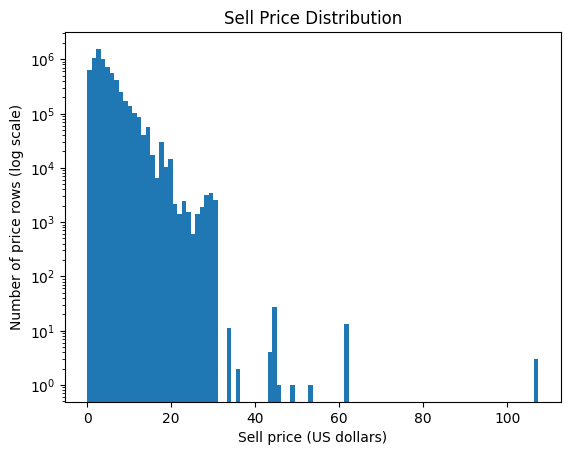

In [ ]:
plt.hist(prices["sell_price"], bins=100)
plt.yscale("log")
plt.title("Sell Price Distribution")
plt.xlabel("Sell price (US dollars)")
plt.ylabel("Number of price rows (log scale)")
plt.show()

In [ ]:
prices.nlargest(5, "sell_price")

,store_id,item_id,wm_yr_wk,sell_price
6485945,WI_3,HOUSEHOLD_2_406,11317,107.32
6485946,WI_3,HOUSEHOLD_2_406,11318,107.32
6485947,WI_3,HOUSEHOLD_2_406,11319,107.32
5805271,WI_2,HOUSEHOLD_2_406,11237,61.46
5805272,WI_2,HOUSEHOLD_2_406,11238,61.46


Graph: Distribution of sell prices for all items and stores (y-axis is log scale).
Observation: Almost all prices are below 30 dollars. Only a few rows have very high prices (up to 107.32). The highest prices belong to a HOUSEHOLD item (HOUSEHOLD_2_406) in Wisconsin stores (WI_2 and WI_3), not to FOODS items in CA_1.

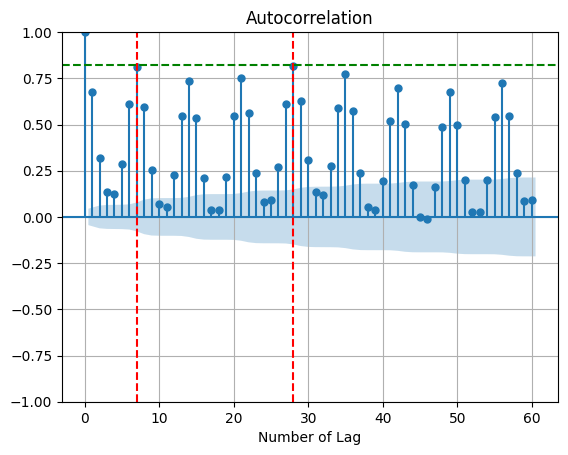

7 0.8158025977895798
28 0.8439259758912275


In [ ]:
total = cal1.set_index("date")["total_sales"]
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(total, lags=60)
plt.axvline(x=7, color='red', linestyle='--')
plt.axvline(x=28, color='red', linestyle='--')
plt.axhline(y=0.82, color='green', linestyle='--')
plt.xlabel("Number of Lag")
plt.grid()
plt.show()

for lag in [7, 28]:
    print(lag, total.corr(total.shift(lag)))

Autocorrelation (ACF)

What it is: Autocorrelation shows how much today's sales are related to the sales from earlier days. "Lag" means how many days earlier. For example, lag 7 compares today with the same weekday last week.

How to read the chart:
- X-axis: lag (days earlier). Y-axis: strength of the relation (-1 to 1).
- A tall bar means a strong relation. Lag 0 is always 1 because it compares a day with itself, so we ignore it.
- Bars outside the blue band are real patterns. Bars inside the band can be chance.

Observation: The correlation of total sales with sales 7 days earlier is 0.82, and with 28 days earlier it is 0.84. Both lags are on the same weekday as today, so the weekly pattern repeats.

Conclusion: We create lag_7 and lag_28 as features. Later we check in the models if both are needed.

## EDA Summary: What we found and what we will do

### What we found
1. The data is clean. There are no duplicates, and the only missing values are in the event columns (empty means no event that day).
2. The calendar has 1,969 days but the sales file has 1,941 days. The extra 28 days have no sales.
3. Sales are right-skewed. Most days have small sales, and only a few days have very high sales. Overall <X>% of the item-days have zero sales.
4. Sales are slowly going up over the years.
5. Sales are higher on weekends and lower in the middle of the week.
6. On Christmas (25 Dec, 2011 to 2015), total sales are only 11 to 20. The stores were almost closed.
7. SNAP days have higher sales in all three states. Event days show little difference from normal days.
8. About 13,000 of the 30,490 series start selling in the first ~40 days. The rest start later. No series has zero sales for all days.
9. Almost all prices are below 30 dollars. The highest prices (up to 107.32) belong to a HOUSEHOLD item in Wisconsin stores.
10. Sales are strongly related to the sales 7 days earlier (0.82) and 28 days earlier (0.84).

### What we will do next
1. Metric: use WAPE as the main metric, with MAE and RMSE. MAPE is not reliable because of the many zero days.
2. Split: use a date-based split (old data for training, new data for testing). Never use a random split.
3. Cleaning: remove the 28 extra calendar days, the 5 Christmas days, and the rows before each series' first sale.
4. Features: add weekday, month, year, has_event, snap flag, sell_price, lag_7 and lag_28.
5. Data size: do EDA on all data, but train the models on one store with all its items (because of Colab memory).

### Things still to check
1. After the merge, check the missing sell_price rows. We think they mean the item was not on sale that week.
2. After the merge, check the price range on our store.
3. In the models, check if both lag_7 and lag_28 are needed.

## Model Selection: Which models can we choose?

### What the EDA tells us about our task
1. Our task is regression, because we predict a number (daily sales).
2. Our data is large. One store has about 5.9 million rows after melting (calculated, not run in code). We train on free Google Colab with CPU only.
3. Our data is tabular, with numbers and categories (weekday, event, SNAP, price, lags).
4. Sales have a weekly pattern, an upward trend, and many zero days. These patterns are not a straight line, so a simple linear model may miss some of them.

### How we shortlisted the models
We checked each model with 4 conditions: (1) is it a regression model, (2) can it handle millions of rows, (3) can it run on free Colab, and (4) does it work well on tabular data.

| Model | Decision | Reason |
|---|---|---|
| Naive (same as yesterday) | Keep (baseline) | No training. Gives the minimum score to beat |
| Same day last week | Keep (baseline) | No training. Fits the weekly pattern |
| Linear Regression | Keep | Fast and simple. Good first model |
| Decision Tree Regressor | Keep | Fast. Can learn non-linear patterns |
| Random Forest Regressor | Keep | Many trees together, usually more accurate. Gives feature importance |
| LightGBM | Keep (bonus) | Built for large data and runs on CPU |
| KNN | Skip | Too slow on millions of rows |
| SVR | Skip | Too slow on millions of rows |
| Naive Bayes | Skip | It is a classification model |
| Logistic Regression | Skip | It is a classification model |

### Final shortlist
Naive baseline, same-day-last-week baseline, Linear Regression, Decision Tree, Random Forest, and LightGBM (if time allows).

### How we will choose the best model
1. Split the data by date: old data for training, newer data for validation, and the newest data for testing.
2. Train every model on the training data.
3. Compare the models on the validation data using WAPE (main metric), MAE and RMSE. MAPE is shown only on non-zero days.
4. A model must beat both baselines. If it does not, we fix the features or data first.
5. If two models have similar scores, we choose the faster and simpler one.
6. Run the best model once on the test data. This is the final score in the report.
7. Finally, compare the models in the inventory simulation (stockouts and extra stock), because the lowest WAPE alone may not give the best reorder decisions.
